# Accuracy: Pitfalls and Edge Cases

This notebook describes OpenDP's accuracy calculations, and ways in which an analyst might be tripped up by them.

### Overview

#### Accuracy vs. Confidence Intervals

Each differentially private mechanism (e.g. Laplace, Gaussian) in OpenDP has an associated accuracy that is a function of alpha and
the noise scale. Imagine you have data $D$, and you want, for some function $\phi$ to return $\phi(D)$ in a
differentially private way -- we will call this value $\phi_{dp}(D)$. An $\alpha$-level accuracy guarantee $a$ promises
that, over infinite runs of the mechanism on the data in question,
$$ \phi(D) \in [\phi_{dp}(D) - a, \phi_{dp}(D) + a] $$
with probability at least $1 - \alpha$.

This looks very much like the traditional confidence interval, but it is important to note a major difference. In a
canonical confidence interval, the uncertainty being represented is due to sampling error -- that is, how often will it
be the case that $\phi(P)$ (the value of $\phi$ on the underlying population) is within some range of the realized
$\phi(D)$.

In OpenDP (and differentially private data analysis generally),
there is an extra layer of uncertainty due to the noise added to $\phi(D)$ to produce $\phi_{dp}(D)$.
OpenDP's accuracy utilities described below deal only with the uncertainty of $\phi_{dp}(D)$ relative to $\phi(D)$
and not the uncertainty of $\phi(D)$ relative to $\phi(P)$, but there is ongoing work to provide methods that incorporate both.

#### What is $D$?

Before any noise is added, OpenDP preprocesses the data.
For example, `.dp.sum()` and `.dp.mean()` clip each value to the bounds you give them,
and they replace any missing values with the midpoint of the bounds.
Call the preprocessed data $\tilde{D}$.
Accuracy guarantees are always relative to $\tilde{D}$:
clipping and imputation are not factored into the accuracy.

#### Synopsis

Say an analyst releases $\phi_{dp}(D)$ and gets an accuracy guarantee of $a$ at accuracy-level $\alpha$.
$D$ is drawn from population $P$ and is preprocessed into $\tilde{D}$.
This suggests that over infinite runs of this procedure,

- $\phi_{dp}(D) \in [\phi(\tilde{D}) - a, \phi(\tilde{D}) + a]$ with probability at least $1 - \alpha$
- It is likely that $\phi_{dp}(D) \in [\phi(D) - a, \phi(D) + a]$ with probability $\approx 1 - \alpha$, though we
cannot make any guarantee. If preprocessing changes little (for example, the bounds contain almost all of the data),
this is likely to be approximately true. If preprocessing changes a lot, it can be badly wrong.
In the next sections, we will explore an example of each.

- We cannot directly make statements about the uncertainty of $\phi_{dp}(D)$ relative to $\phi(P)$.

### Setup

We use the California PUMS sample that ships with OpenDP, and we look at people's ages.
Its published name, `PUMS_california_demographics_1000`, says it has 1,000 people,
so we treat that size as public knowledge.
Age has no missing values, so the midpoint imputation above never comes into play here.
We also compute the exact mean age.
It is not differentially private; we use it only to check the DP releases against the truth.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import opendp.prelude as dp
import polars as pl

dp.enable_features("contrib")

data = pl.scan_csv(
    dp.examples.get_california_pums_path(),
    has_header=False,
    new_columns=["age", "sex", "educ", "race", "income", "married"],
    # Some incomes are written like "1e+05", so they can't be read as integers.
    schema_overrides={"income": pl.Float64},
)

ages = data.select("age").collect()["age"]
D_mean_age = ages.mean()
print(f"{len(ages)} people, ages {ages.min():.0f} to {ages.max():.0f}")
print(f"true mean age: {D_mean_age:.3f}")

1000 people, ages 18 to 93
true mean age: 44.797


### Pitfall: the accuracy of a mean is not reported directly

The natural way to release a mean is `.dp.mean()`.
It needs an upper bound on the number of rows in the data, which we give as a margin.
OpenDP uses it to rule out overflow in the sum.
It must come from public knowledge (here, the published sample size), not from looking at the data.
If the length did come from looking at the private data,
then the privacy guarantee would no longer hold.

In [2]:
context = dp.Context.compositor(
    data=data,
    privacy_unit=dp.unit_of(contributions=1),
    privacy_loss=dp.loss_of(epsilon=1.0),
    split_evenly_over=1,
    margins=[dp.polars.Margin(max_length=1000)],
)

context.query().select(pl.col("age").dp.mean((0.0, 100.0))).summarize(alpha=0.05)

column,aggregate,distribution,scale,accuracy
str,str,str,f64,f64
"""age""","""Sum""","""Integer Laplace""",200.0,599.64583
"""age""","""Length""","""Integer Laplace""",2.0,6.429605


`summarize()` only describes the noise. It releases nothing and spends no budget.

There are two rows, and neither of them is the mean.
`.dp.mean()` releases a noisy sum and a noisy count, and divides one by the other.
It splits the budget evenly, $\epsilon = 0.5$ each,
so the noise scales are $100 / 0.5 = 200$ for the sum (one person changes it by at most 100)
and $1 / 0.5 = 2$ for the count.
The summary gives the accuracy of each part:
the sum is within about 600 of the true sum, and the count is within about 6 of the true count,
each with probability 95%.
The 600 is in person-years, not years. As we will see, the interval for the mean is only about ±1 year.

To get an interval for the mean, we release the two parts ourselves, which costs the same privacy budget.
Suppose the noisy sum $S$ is within $a_S$ of the true sum, and the noisy count $N$ is within $a_N$ of the true count.
Ages are never negative, so the true sum is too.
Then the smallest the true mean can be is the smallest possible sum over the largest possible count,
and the largest is the reverse:
$$ \frac{\max(0, S - a_S)}{N + a_N} \quad \text{and} \quad \frac{S + a_S}{N - a_N}. $$
This needs $N > a_N$; otherwise the upper end is unbounded, and we fall back to the upper clipping bound.
Since the clipped mean always lies within the clipping bounds, we also cap the interval there.
We ask for each part at $\alpha / 2$, so that both hold together with probability at least $1 - \alpha$.
The interval is not symmetric around $S / N$, but it plays the same role as $\phi_{dp}(D) \pm a$ above.

In [3]:
alpha = 0.05


def mean_interval_query(bounds):
    return context.query().select(
        pl.col("age").dp.sum(bounds).alias("sum"),
        pl.col("age").dp.len(signed=True).alias("len"),
    )


query = mean_interval_query((0.0, 100.0))
query.summarize(alpha=alpha / 2)

column,aggregate,distribution,scale,accuracy
str,str,str,f64,f64
"""sum""","""Sum""","""Integer Laplace""",200.0,738.275266
"""len""","""Length""","""Integer Laplace""",2.0,7.815899


The scales match the two rows from `.dp.mean()`, so this is the same release with the parts kept separate.
The accuracies are larger because we asked for $\alpha / 2$ instead of $\alpha$.

### Example 1: bounds that contain all the data

To see how often the interval contains the truth, we release it many times.
In a real analysis you would release it once.
As in the [signed counts recipe](signed-counts.py), `query.resolve()` gives a measurement we can call repeatedly.
Each call costs another $\epsilon = 1$, and calling it directly skips the Context's budget check.
The 400 releases below (200 for each example) add up to $\epsilon = 400$, and nothing stops or records that.
Only do this for demonstrations like this one, never with data you need to protect.

In [4]:
n_repeats = 200


def release_intervals(bounds):
    query = mean_interval_query(bounds)
    # the interval below relies on every clipped value being non-negative
    assert bounds[0] >= 0
    summary = query.summarize(alpha=alpha / 2)
    a_sum = summary.filter(pl.col("column") == "sum")["accuracy"].item()
    a_len = summary.filter(pl.col("column") == "len")["accuracy"].item()
    measurement = query.resolve()
    releases = pl.concat([measurement(data).collect() for _ in range(n_repeats)])
    S = releases["sum"].to_numpy()
    N = releases["len"].cast(pl.Float64).to_numpy()
    # if the noisy count is too small to bound the mean, fall back to the clipping bounds
    ok = N > a_len
    safe_N = np.where(ok, N, a_len + 1)
    lower = np.where(
        ok, np.maximum(bounds[0], (S - a_sum) / (safe_N + a_len)), bounds[0]
    )
    upper = np.where(
        ok, np.minimum(bounds[1], (S + a_sum) / (safe_N - a_len)), bounds[1]
    )
    return S / N, lower, upper


def coverage(lower, upper, target):
    return np.mean((lower <= target) & (target <= upper))


wide_bounds = (0.0, 100.0)
wide_mean, wide_lower, wide_upper = release_intervals(wide_bounds)
D_tilde_wide = ages.clip(*wide_bounds).mean()

print(f"average interval width: {np.mean(wide_upper - wide_lower):.2f} years")
print(
    f"contains the mean of D_tilde: {coverage(wide_lower, wide_upper, D_tilde_wide):.0%}"
)
print(
    f"contains the mean of D:       {coverage(wide_lower, wide_upper, D_mean_age):.0%}"
)

average interval width: 2.18 years
contains the mean of D_tilde: 100%
contains the mean of D:       100%


The oldest person is 93, so clipping to $[0, 100]$ changes nothing, and $D$ and $\tilde{D}$ are the same data.
The guarantee on $\tilde{D}$ carries over exactly to $D$.
The coverage is above 95% because the interval is conservative:
it assumes the sum and the count are both off by their full accuracy, in the worst directions, at once.

### Example 2: bounds that are too narrow

Now suppose the analyst guesses the bounds $[0, 60]$.
No one would choose this for age on purpose; it stands in for any case where the bounds cut off real values.
About a fifth of the people are older than 60, and their ages are clipped down to 60 before any noise is added.
The narrower bounds also mean less noise (the sum's noise scale drops from 200 to 120), so the interval gets tighter.

In [5]:
narrow_bounds = (0.0, 60.0)
narrow_mean, narrow_lower, narrow_upper = release_intervals(narrow_bounds)
D_tilde_narrow = ages.clip(*narrow_bounds).mean()

print(f"share of people older than 60: {(ages > 60).mean():.0%}")
print(f"mean of D_tilde: {D_tilde_narrow:.3f}, mean of D: {D_mean_age:.3f}")
print(f"average interval width: {np.mean(narrow_upper - narrow_lower):.2f} years")
print(
    f"contains the mean of D_tilde: {coverage(narrow_lower, narrow_upper, D_tilde_narrow):.0%}"
)
print(
    f"contains the mean of D:       {coverage(narrow_lower, narrow_upper, D_mean_age):.0%}"
)

share of people older than 60: 20%
mean of D_tilde: 42.148, mean of D: 44.797
average interval width: 1.55 years
contains the mean of D_tilde: 100%
contains the mean of D:       0%


The guarantee still holds for $\tilde{D}$, as it must.
But the clipped mean is more than two years below the true mean, and the interval is under two years wide,
so it essentially never contains the true mean of $D$.
Here are the first 50 of the 200 intervals from each example.
In the left panel the two vertical lines are on top of each other, because $D$ and $\tilde{D}$ are the same.

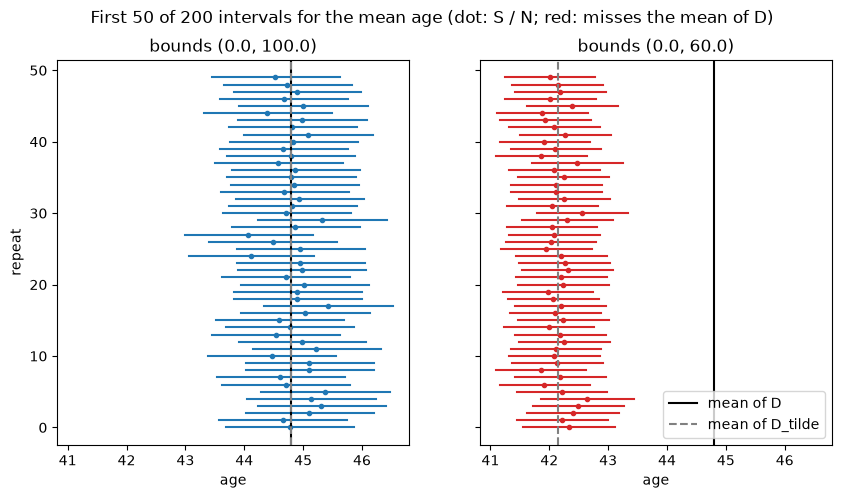

In [6]:
n_show = 50
fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
examples = [
    (axes[0], wide_bounds, wide_mean, wide_lower, wide_upper),
    (axes[1], narrow_bounds, narrow_mean, narrow_lower, narrow_upper),
]
for ax, bounds, mean, lower, upper in examples:
    hits = (lower <= D_mean_age) & (D_mean_age <= upper)
    for i in range(n_show):
        color = "tab:blue" if hits[i] else "tab:red"
        ax.plot([lower[i], upper[i]], [i, i], color=color)
        ax.plot(mean[i], i, "o", color=color, markersize=3)  # the release S / N
    ax.axvline(D_mean_age, color="black", label="mean of D")
    ax.axvline(
        ages.clip(*bounds).mean(), color="gray", linestyle="--", label="mean of D_tilde"
    )
    ax.set_title(f"bounds {bounds}")
    ax.set_xlabel("age")
axes[0].set_ylabel("repeat")
axes[1].legend(loc="lower right")
fig.suptitle(
    "First 50 of 200 intervals for the mean age (dot: S / N; red: misses the mean of D)"
)
plt.show()

### Takeaways

- An accuracy guarantee is about the preprocessed data $\tilde{D}$.
  It carries over to the raw data only if preprocessing changed little.
- Narrow bounds reduce the noise, and so make the interval tighter, but they can move the target.
  A tight interval around the wrong value can look more trustworthy than a wide one around the right value.
  Choose bounds from public knowledge about what values are possible, not from what makes the interval small.
- Tight clipping is not always a mistake. It trades bias for less noise, and for heavy-tailed data such as income
  it can be a good trade. Just remember that the accuracy then describes the clipped value.
  To see how much was clipped, you can spend a little budget on a DP count of the values at or above the upper bound.
- `.dp.mean()` reports the accuracy of its sum and its count, not of the mean.
  To get an interval for the mean, release the sum and the count and combine their accuracies,
  as we did above.